# data preparation

aggregating raw transactions into daily sales for our top categories and filling any missing dates with 0.


In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt


### aggregating daily sales

using duckdb to stream transactions and group by date and category so we don't run out of ram.


In [2]:
con = duckdb.connect()

categories = [
    "Garment Upper body",
    "Garment Lower body",
    "Garment Full body",
    "Swimwear",
    "Underwear",
    "Accessories"
]

sales = con.execute("""
    SELECT t_dat as date, product_group_name as category, COUNT(*) as units_sold
    FROM read_csv_auto('data/raw/transactions_train.csv')
    JOIN read_csv_auto('data/raw/articles.csv')
    USING (article_id)
    GROUP BY t_dat, product_group_name
""").df()

sales = sales[sales["category"].isin(categories)]
sales["date"] = sales["date"].astype(str)

sales.head()


,date,category,units_sold
0,2018-09-20,Garment Lower body,11868
1,2018-09-20,Accessories,2194
6,2018-09-21,Swimwear,1247
8,2018-09-26,Garment Lower body,11195
9,2018-09-26,Accessories,2589


### creating calendar grid and zero-filling

prophet needs every date present. we create a full grid of all 734 days for our 6 categories and fill missing days with 0.


In [3]:
all_dates = pd.date_range("2018-09-20", "2020-09-22").strftime("%Y-%m-%d")
grid = pd.MultiIndex.from_product([all_dates, categories], names=["date", "category"]).to_frame().reset_index(drop=True)

df = pd.merge(grid, sales, on=["date", "category"], how="left")
df["units_sold"] = df["units_sold"].fillna(0).astype(int)
df = df.sort_values(["category", "date"]).reset_index(drop=True)

print("shape:", df.shape)
df.head()


shape: (4404, 3)


,date,category,units_sold
0,2018-09-20,Accessories,2194
1,2018-09-21,Accessories,2269
2,2018-09-22,Accessories,836
3,2018-09-23,Accessories,2086
4,2018-09-24,Accessories,2092


### checking the output

making sure every category has exactly 734 days and no missing values.


In [4]:
for cat in categories:
    sub = df[df["category"] == cat]
    print(cat, len(sub), "days, nulls:", sub["units_sold"].isnull().sum(), "total units:", sub["units_sold"].sum())


Garment Upper body 734 days, nulls: 0 total units: 12552755
Garment Lower body 734 days, nulls: 0 total units: 7046054
Garment Full body 734 days, nulls: 0 total units: 3552470
Swimwear 734 days, nulls: 0 total units: 2579222
Underwear 734 days, nulls: 0 total units: 2565858
Accessories 734 days, nulls: 0 total units: 1599593


### plotting daily sales

let's look at the daily sales for each category.


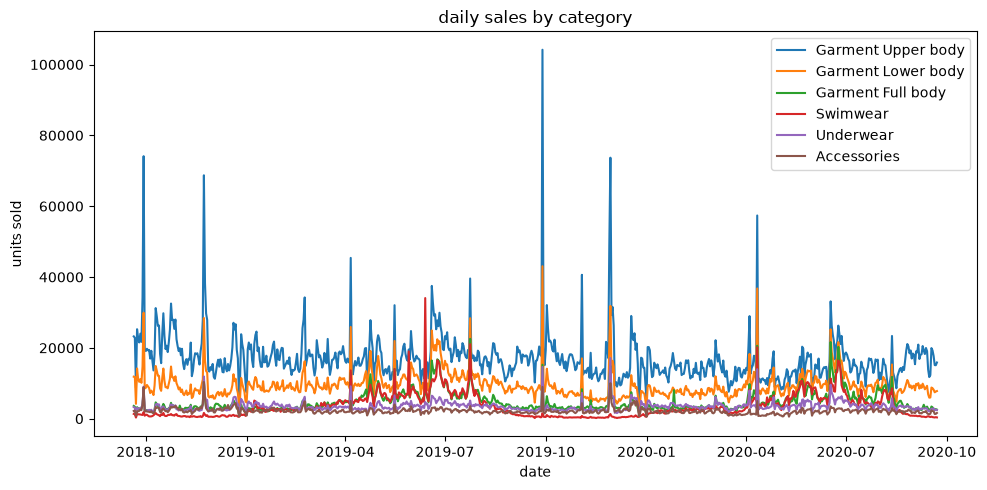

In [5]:
df["date"] = pd.to_datetime(df["date"])

plt.figure(figsize=(10, 5))
for cat in categories:
    sub = df[df["category"] == cat]
    plt.plot(sub["date"], sub["units_sold"], label=cat)

plt.title("daily sales by category")
plt.xlabel("date")
plt.ylabel("units sold")
plt.legend()
plt.tight_layout()
plt.show()


### saving the dataset

saving to data/processed/daily_category_sales.csv for the next notebook.


In [6]:
df.to_csv("data/processed/daily_category_sales.csv", index=False)
print("saved data/processed/daily_category_sales.csv")


saved data/processed/daily_category_sales.csv
